# Skewness in Data: distplot and log1p
### How to see skewness, and how to fix it

In this notebook we will go step by step:
1. What is skewness (types, mean vs median)
2. How to check skewness with numbers (`.skew()`)
3. How to see skewness with a graph (`distplot`)
4. Why skewness is a problem
5. How to handle it with **log1p**
6. Other methods (short overview)
7. Full example on a dataset

## Step 0: Import libraries and make a dataset

Real data is better, but to keep everything in one notebook I am making a fake dataset with `numpy`. `np.random.seed(42)` makes sure you get the same numbers as me every time.

Columns:
- **Age**: normal shape, almost no skew
- **Salary**: few people earn a lot, most earn less (right skewed)
- **Purchases**: number of purchases in a month, many people have 0 (right skewed with zeros, important for log1p)
- **ExamScore**: most students score high, few score low (left skewed)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

np.random.seed(42)
n = 1000

df = pd.DataFrame({
    "Age":       np.random.normal(loc=35, scale=8, size=n).round(0),
    "Salary":    np.random.lognormal(mean=10.5, sigma=0.8, size=n).round(0),
    "Purchases": np.random.poisson(lam=1.2, size=n) ** 2,
    "ExamScore": (100 - np.random.exponential(scale=12, size=n)).clip(0, 100).round(1),
})

df.head()

,Age,Salary,Purchases,ExamScore
0,39.0,111244.0,1,99.2
1,34.0,76093.0,1,84.6
2,40.0,38090.0,4,68.3
3,47.0,21643.0,4,93.2
4,33.0,63486.0,0,98.5


In [2]:
df.describe()

,Age,Salary,Purchases,ExamScore
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.165000,52623.250000,2.595000,88.243400
std,7.851715,48032.166935,4.111189,11.788981
min,9.000000,3455.000000,0.000000,19.400000
25%,30.000000,22359.500000,0.000000,83.800000
50%,35.000000,38195.000000,1.000000,92.300000
75%,40.000000,65062.500000,4.000000,96.700000
max,66.000000,467188.000000,36.000000,100.000000


---
# 1. What is Skewness?

### Definition
**Skewness tells how asymmetric (not balanced) the data distribution is.**

If you draw a histogram and the left and right side look like mirror images, the data is symmetric (like a bell curve). If one side has a long tail, the data is skewed.

### Types of skewness

| Type | Tail direction | Skewness value | Mean vs Median | Example |
|---|---|---|---|---|
| **Positive (Right) skew** | Long tail on the right | > 0 | Mean > Median | Salary, house price, city population |
| **Zero skew (Symmetric)** | Both sides equal | about 0 | Mean = Median | Height, Age (roughly) |
| **Negative (Left) skew** | Long tail on the left | < 0 | Mean < Median | Exam scores of easy exam, age of death |

Easy way to remember: **the tail gives the name.** Tail on right = right skewed = positive skew.

Why does the mean move? Because the mean is pulled by extreme values in the tail, but the median stays in the middle.

### Rule of thumb for skewness value

| Skewness value | Meaning |
|---|---|
| -0.5 to +0.5 | Fairly symmetric, no need to fix |
| 0.5 to 1 (or -0.5 to -1) | Moderately skewed |
| above 1 (or below -1) | Highly skewed, should fix |

These are only guidelines, not strict rules.

---
# 2. Checking skewness with numbers

### Syntax
```python
df.skew()                 # pandas, for all numeric columns
df["col"].skew()          # one column

from scipy.stats import skew
skew(df["col"])           # scipy version
```
Pandas and scipy give slightly different numbers because they use different formulas (pandas applies a small sample-size correction). For a big dataset the difference is tiny.

In [3]:
print(df.skew())

Age          0.116167
Salary       2.907719
Purchases    3.229728
ExamScore   -1.743389
dtype: float64


In [4]:
# mean vs median check, tail pulls the mean
check = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Skew": df.skew()
})
check["Mean - Median"] = check["Mean"] - check["Median"]
check.round(2)

,Mean,Median,Skew,Mean - Median
Age,35.16,35.0,0.12,0.16
Salary,52623.25,38195.0,2.91,14428.25
Purchases,2.60,1.0,3.23,1.60
ExamScore,88.24,92.3,-1.74,-4.06


How to read it:
- **Age**: skew is near 0 and mean is close to median, so symmetric.
- **Salary**: big positive skew, mean is much higher than median, so right skewed.
- **Purchases**: positive skew, right skewed.
- **ExamScore**: negative skew, mean is lower than median, so left skewed.

---
# 3. Seeing skewness with distplot

### Definition
`sns.distplot()` is a **seaborn** function that draws a **histogram + a smooth KDE curve** together for one numeric column. It is the quickest way to see the shape of the data.

- **Histogram bars**: how many values fall in each range (bin).
- **KDE line** (Kernel Density Estimate): a smooth line over the bars showing the overall shape.

### Syntax
```python
import seaborn as sns

sns.distplot(df["column"], bins=30, kde=True, color="blue")
```

| Parameter | What it does |
|---|---|
| first argument | one column (1D data) |
| `bins=30` | number of bars in the histogram |
| `kde=True` | draw the smooth curve (default True) |
| `color="..."` | colour of the plot |
| `hist=False` | show only the KDE line, no bars |

### Important note
`distplot` is **deprecated** (old) in newer seaborn versions. It still runs in Colab, but you will see a `FutureWarning`. That is normal, nothing is broken. The new replacements are `sns.histplot(..., kde=True)` for a single plot and `sns.displot(...)` for a figure-level plot. Many tutorials and interviews still use `distplot`, so it is good to know both. I show the new one at the end of this section.

/tmp/ipykernel_2537/1109670049.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Age"], bins=30, color="green")


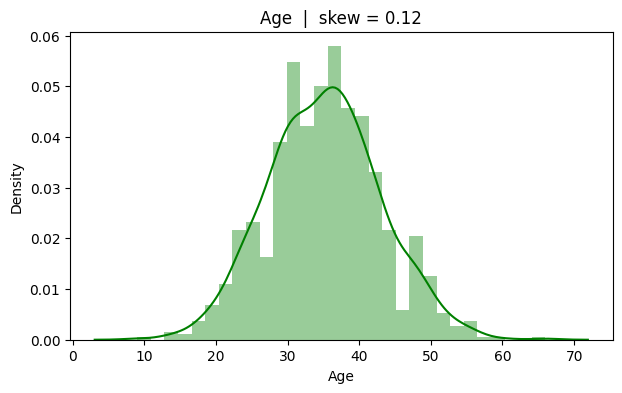

In [5]:
# Age: looks like a bell curve (symmetric)
plt.figure(figsize=(7, 4))
sns.distplot(df["Age"], bins=30, color="green")
plt.title(f"Age  |  skew = {df['Age'].skew():.2f}")
plt.show()

/tmp/ipykernel_2537/2121088683.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Salary"], bins=30, color="red")


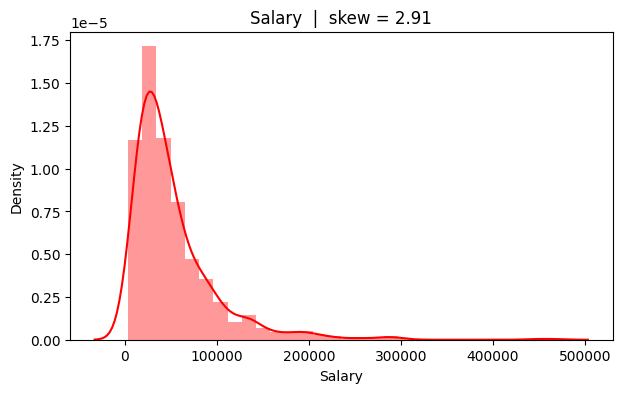

In [6]:
# Salary: long tail on the right (positive skew)
plt.figure(figsize=(7, 4))
sns.distplot(df["Salary"], bins=30, color="red")
plt.title(f"Salary  |  skew = {df['Salary'].skew():.2f}")
plt.show()

/tmp/ipykernel_2537/2521966136.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["ExamScore"], bins=30, color="blue")


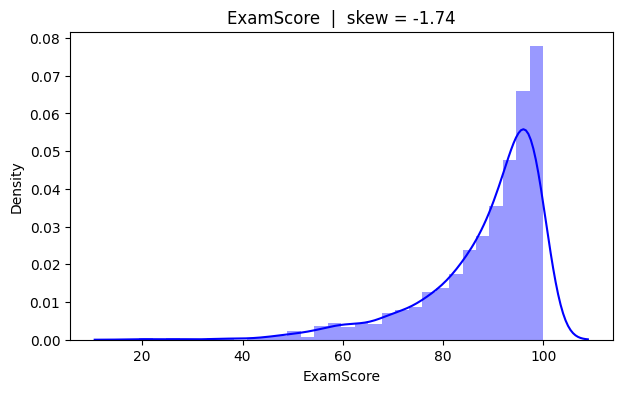

In [7]:
# ExamScore: long tail on the left (negative skew)
plt.figure(figsize=(7, 4))
sns.distplot(df["ExamScore"], bins=30, color="blue")
plt.title(f"ExamScore  |  skew = {df['ExamScore'].skew():.2f}")
plt.show()

### How to read these graphs
- **Age**: the bars rise to the middle and fall equally on both sides. Symmetric.
- **Salary**: most bars are bunched on the left and a thin tail goes far to the right. Right skewed.
- **ExamScore**: most bars are on the right (high scores) and the tail goes to the left. Left skewed.

Let's draw all four columns in one figure so we can compare easily.

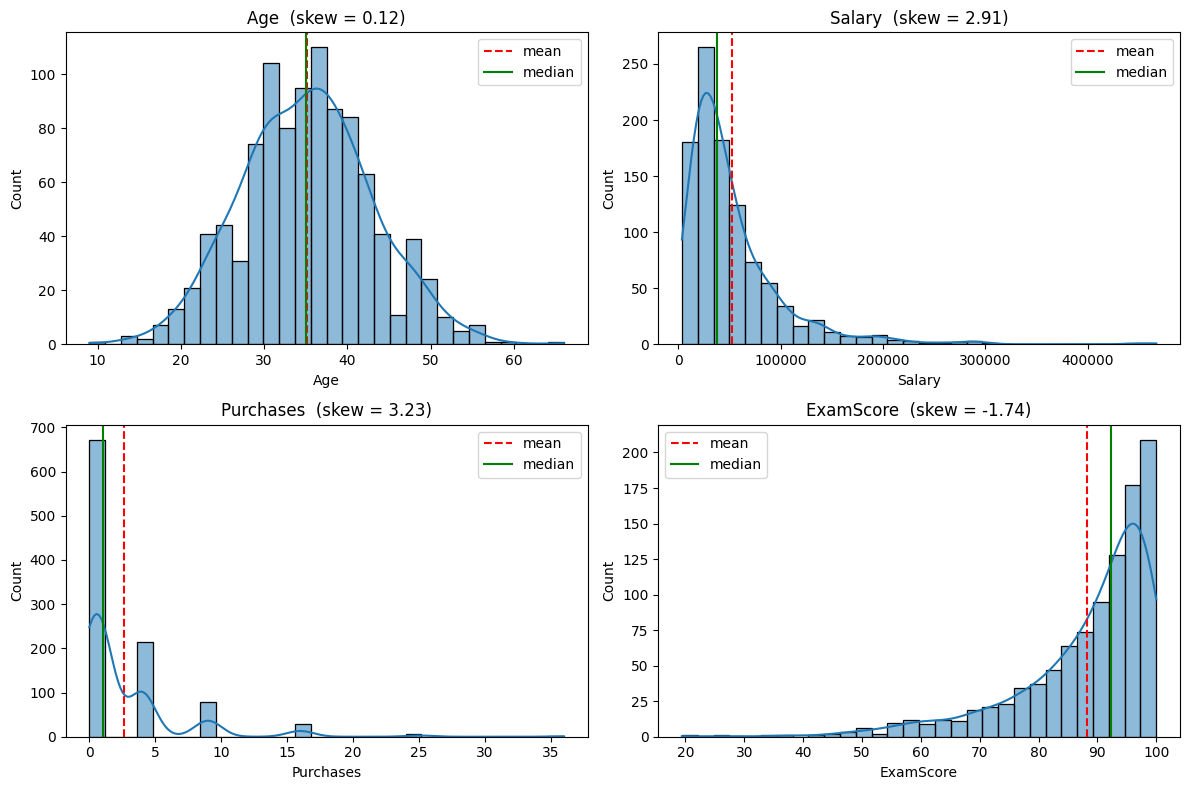

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, bins=30, ax=ax)     # new way, same idea as distplot
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="green", linestyle="-", label="median")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.legend()

plt.tight_layout()
plt.show()

The red dashed line is the mean and the green line is the median. In the skewed columns they are far apart, and the mean sits towards the tail. In Age they almost overlap.

### Advantages of distplot
- Histogram and smooth curve in one line of code.
- Easy to see skew, outliers and the general shape.
- Good for EDA (exploratory data analysis).

### Disadvantages of distplot
- **Deprecated**, so it may be removed in future seaborn versions. Use `histplot` / `displot` for new code.
- Only 1 column at a time (we need a loop for many columns).
- Shape depends on the `bins` value. Too few or too many bins can mislead.
- It shows the skew only visually, no exact number. So always use it with `.skew()`.

---
# 4. Why is skewness a problem?

Skewed data can hurt a model in these ways:

- **Linear Regression, Logistic Regression** and other models assume the data (or the errors) is roughly normal. Heavy skew breaks this and gives weaker predictions.
- The **long tail has outliers**. They pull the mean and the model line towards them.
- **Distance-based models** (KNN, SVM, K-Means) get confused because a few huge values dominate the distance.
- Statistical tests (t-test, ANOVA) assume normality.

Note: tree models (Decision Tree, Random Forest, XGBoost) are not very affected by skew, because they only split on order of values, not on the actual size.

So for many models we **reduce the skew first**. One of the most popular ways is the log transformation.

---
# 5. Handling skewness with log1p

### What is a log transformation?
Log **squeezes big numbers a lot and small numbers only a little**. Look at this:

| Value | log(value) |
|---|---|
| 10 | 2.30 |
| 100 | 4.61 |
| 1,000 | 6.91 |
| 1,000,000 | 13.82 |

The value grew 100,000 times (10 to 1,000,000) but the log only grew about 6 times. So the long right tail gets pulled in and the shape becomes more bell-like.

### Why log1p and not just log?
- `np.log(x)` has a problem: **log(0) = -infinity** and log of a negative number gives NaN.
- `np.log1p(x)` calculates **log(1 + x)**. So log1p(0) = log(1) = 0, which is safe.

Many real columns have zeros (number of purchases, kids, claims, sales). So `log1p` is the safe choice.

### Syntax
```python
import numpy as np

df["col_log"] = np.log1p(df["col"])      # apply the transform
df["col_back"] = np.expm1(df["col_log"]) # reverse it: exp(x) - 1
```

`np.expm1` is the exact opposite of `np.log1p`. You need it to bring predictions back to the original scale.

In [9]:
# Problem with plain log when data has zeros
print("Zeros in Purchases:", (df["Purchases"] == 0).sum())

with np.errstate(divide="ignore"):
    print("np.log  ->", np.log(df["Purchases"]).head(8).values)

print("np.log1p ->", np.log1p(df["Purchases"]).head(8).values)

Zeros in Purchases: 305
np.log  -> [0.         0.         1.38629436 1.38629436       -inf 1.38629436
       -inf       -inf]
np.log1p -> [0.69314718 0.69314718 1.60943791 1.60943791 0.         1.60943791
 0.         0.        ]


`np.log` gives `-inf` on the zeros, which will break a model. `np.log1p` handles them correctly.

Now let's apply log1p on Salary and check before vs after.

In [10]:
df["Salary_log1p"] = np.log1p(df["Salary"])

print("Skew before:", round(df["Salary"].skew(), 3))
print("Skew after :", round(df["Salary_log1p"].skew(), 3))

Skew before: 2.908
Skew after : -0.049


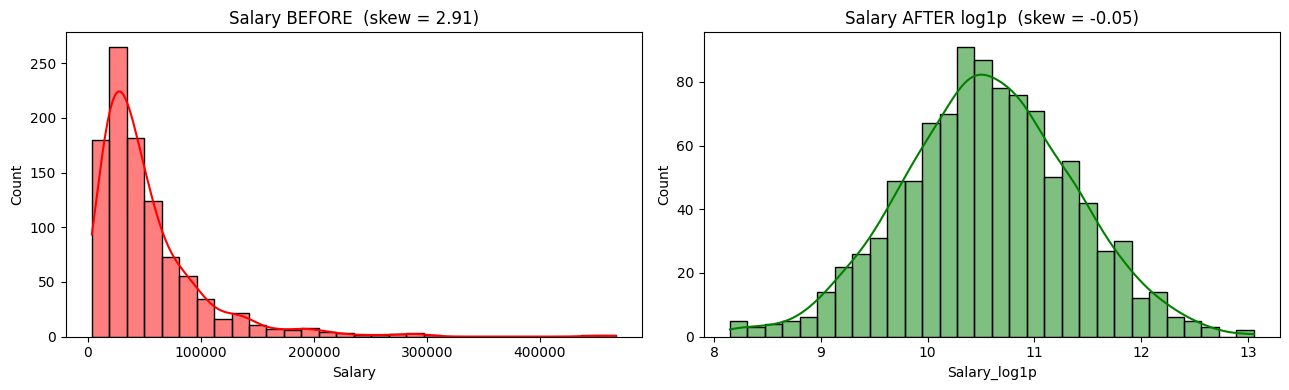

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["Salary"], kde=True, bins=30, color="red", ax=axes[0])
axes[0].set_title(f"Salary BEFORE  (skew = {df['Salary'].skew():.2f})")

sns.histplot(df["Salary_log1p"], kde=True, bins=30, color="green", ax=axes[1])
axes[1].set_title(f"Salary AFTER log1p  (skew = {df['Salary_log1p'].skew():.2f})")

plt.tight_layout()
plt.show()

The long tail is gone and the shape is now close to a bell curve. The skew value went from a large positive number to nearly zero.

Same thing for Purchases (the column with zeros):

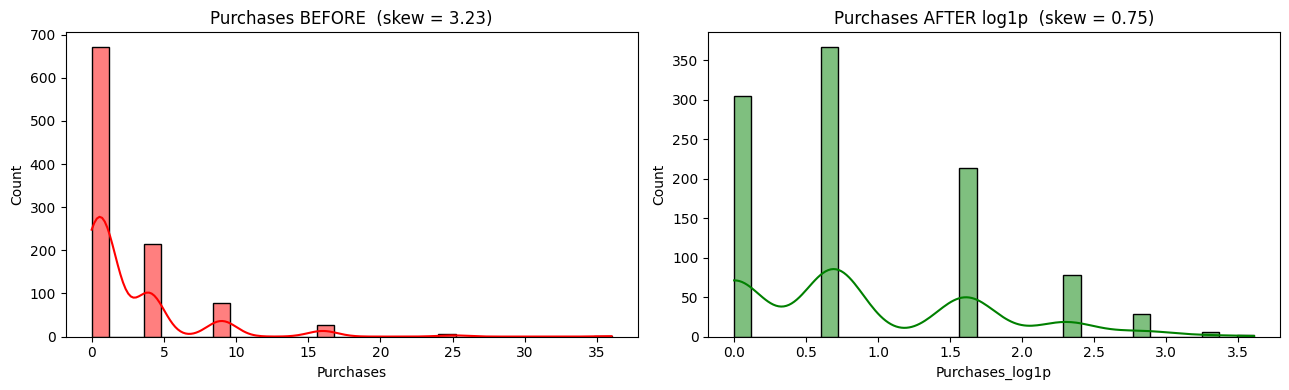

In [12]:
df["Purchases_log1p"] = np.log1p(df["Purchases"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["Purchases"], kde=True, bins=30, color="red", ax=axes[0])
axes[0].set_title(f"Purchases BEFORE  (skew = {df['Purchases'].skew():.2f})")

sns.histplot(df["Purchases_log1p"], kde=True, bins=30, color="green", ax=axes[1])
axes[1].set_title(f"Purchases AFTER log1p  (skew = {df['Purchases_log1p'].skew():.2f})")

plt.tight_layout()
plt.show()

The skew is reduced here as well, but notice the bars: this column is a count (0, 1, 4, 9 ...), so it will never become a perfect bell curve. Log1p can reduce skew, but it can not make every column perfectly normal.

### Getting the original values back (inverse)
After training a model on the log values, the predictions are also in log scale. We use `np.expm1` to convert back.

In [13]:
back = np.expm1(df["Salary_log1p"])

# check that we really got the original salary back
print("Same as original?", np.allclose(back, df["Salary"]))
pd.DataFrame({"Original": df["Salary"], "log1p": df["Salary_log1p"].round(3), "expm1 (back)": back.round(0)}).head()

Same as original? True


,Original,log1p,expm1 (back)
0,111244.0,11.619,111244.0
1,76093.0,11.240,76093.0
2,38090.0,10.548,38090.0
3,21643.0,9.982,21643.0
4,63486.0,11.059,63486.0


### What about left-skewed data (ExamScore)?
Log works for **right skew**. If we apply log1p to a left-skewed column it can make things worse. Look:

In [14]:
print("ExamScore skew original :", round(df["ExamScore"].skew(), 3))
print("ExamScore after log1p   :", round(np.log1p(df["ExamScore"]).skew(), 3))

ExamScore skew original : -1.743
ExamScore after log1p   : -2.813


It did not help, the column is still left skewed. For left skew, first **reflect** the data (flip it into a right skew) and then apply log1p:

`new_value = (max + 1) - value`

This turns the small values into big ones, so the tail moves to the right. Then log1p can work.

In [15]:
max_val = df["ExamScore"].max()

df["ExamScore_reflect"] = (max_val + 1) - df["ExamScore"]       # flip the tail to the right
df["ExamScore_fixed"]   = np.log1p(df["ExamScore_reflect"])     # then log1p

print("Original skew :", round(df["ExamScore"].skew(), 3))
print("Reflected skew:", round(df["ExamScore_reflect"].skew(), 3))
print("After log1p   :", round(df["ExamScore_fixed"].skew(), 3))

Original skew : -1.743
Reflected skew: 1.743
After log1p   : 0.086


Remember: after reflecting, the **order of the values is reversed** (high score is now a low number). That matters when you explain results. This is one reason people sometimes use other methods for left skew (see next section).

### Advantages of log1p
- Very easy, one line: `np.log1p(x)`.
- **Safe with zeros** (unlike `np.log`).
- Strongly reduces right skew and the effect of big outliers.
- Reversible with `np.expm1`.
- Good for money, population, counts, prices, sales etc.

### Disadvantages of log1p
- **Only works for values > -1** (zero and positive numbers are fine). Negative numbers below -1 give NaN.
- Made for **right skew**. Left skew needs reflecting first.
- Not perfect: it does not always give a normal distribution.
- Results are in log scale, so you must convert back (`expm1`) to explain it in real units.
- Changes the meaning of the numbers: a linear model now learns "percentage change" type relations, not plain unit changes.
- The data is not always improved. Always check `.skew()` or a plot afterwards.

---
# 6. Other methods (short overview)

log1p is not the only way. Here is a quick table:

| Method | Code | Works for | Notes |
|---|---|---|---|
| **log1p** | `np.log1p(x)` | Right skew, values >= 0 | Simple and common |
| **Square root** | `np.sqrt(x)` | Right skew, values >= 0 | Weaker than log, good for mild skew |
| **Reciprocal** | `1 / x` | Strong right skew, no zeros | Reverses the order of values |
| **Square / Cube** | `x ** 2` | Left skew | Pulls the left tail in |
| **Box-Cox** | `PowerTransformer(method="box-cox")` | Right skew, values > 0 only | Finds the best power automatically |
| **Yeo-Johnson** | `PowerTransformer(method="yeo-johnson")` | Right or left skew, **any values** (also negative) | Most flexible, default of PowerTransformer |

Let's try Yeo-Johnson once because it handles both skew directions, so it also solves our ExamScore column.

In [16]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")
yj = pt.fit_transform(df[["Salary", "Purchases", "ExamScore"]])
yj = pd.DataFrame(yj, columns=["Salary_yj", "Purchases_yj", "ExamScore_yj"])

print(yj.skew().round(3))

Salary_yj       0.000
Purchases_yj    0.158
ExamScore_yj   -0.412
dtype: float64


Yeo-Johnson made all three columns much closer to symmetric, including the left-skewed ExamScore. So for a quick fix on many columns, `PowerTransformer` is handy. But log1p is easier to explain to people and easy to reverse, so it is still very popular.

---
# 7. Full example: check all columns, fix only the skewed ones

In a real project we do not fix columns by hand one by one. We loop over the numeric columns, check skew and apply log1p only where the skew is above 1.

In [17]:
data = df[["Age", "Salary", "Purchases", "ExamScore"]].copy()    # fresh copy of original columns

skew_before = data.skew()
print("Skew before:\n", skew_before.round(3), "\n")

for col in data.columns:
    if data[col].skew() > 1:                  # only right skewed, highly
        data[col] = np.log1p(data[col])
        print(f"log1p applied on: {col}")

print("\nSkew after:\n", data.skew().round(3))

Skew before:
 Age          0.116
Salary       2.908
Purchases    3.230
ExamScore   -1.743
dtype: float64 

log1p applied on: Salary
log1p applied on: Purchases

Skew after:
 Age          0.116
Salary      -0.049
Purchases    0.753
ExamScore   -1.743
dtype: float64


In [18]:
# before vs after in one table
result = pd.DataFrame({"Skew before": skew_before, "Skew after": data.skew()}).round(3)
result

,Skew before,Skew after
Age,0.116,0.116
Salary,2.908,-0.049
Purchases,3.230,0.753
ExamScore,-1.743,-1.743


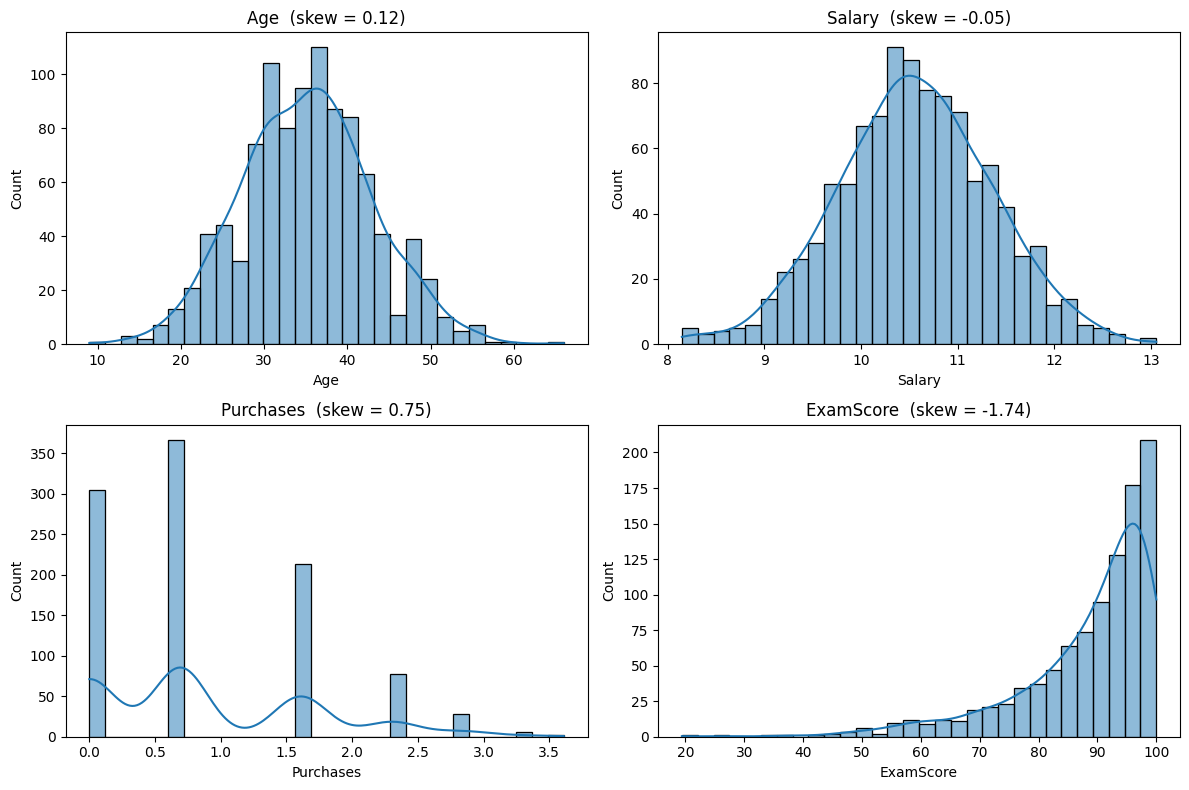

In [19]:
# final look at all columns
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), data.columns):
    sns.histplot(data[col], kde=True, bins=30, ax=ax)
    ax.set_title(f"{col}  (skew = {data[col].skew():.2f})")

plt.tight_layout()
plt.show()

Age was not touched (already symmetric). Salary and Purchases were fixed with log1p. ExamScore is left skewed, so our "skew > 1" rule skipped it. It needs the reflect trick or Yeo-Johnson.

---
# Summary

| Topic | One line to remember |
|---|---|
| Skewness | How lopsided the distribution is. Tail on right = positive skew |
| Check with numbers | `df.skew()` (above 1 or below -1 is high) |
| Check with graph | `sns.distplot()` (old) or `sns.histplot(kde=True)` (new) |
| Mean vs median | In right skew mean > median, in left skew mean < median |
| log1p | `np.log1p(x)` = log(1 + x), fixes right skew, safe with zeros |
| Reverse | `np.expm1(x)` |
| Left skew | Reflect first `(max + 1) - x`, then log1p, or use Yeo-Johnson |

### Common mistakes to avoid
- Using `np.log` on a column with zeros (gives `-inf`).
- Applying log1p on left-skewed data and expecting it to work.
- Forgetting `np.expm1` when converting model predictions back to real units.
- Fixing skew for tree models where it is not needed.
- Applying the transform on the whole dataset before the train/test split with fitted transformers like PowerTransformer (fit on train only). log1p has no fitting, so it is safe either way.
- Trusting only the graph. Always check `.skew()` too.

### Practice task
Download the **House Prices** dataset from Kaggle. Check the skew of `SalePrice` and `LotArea` with distplot and `.skew()`, apply `np.log1p`, and compare before vs after.